# Model Training: Pneumonia Detection

Two-stage training: frozen backbone → full fine-tuning

In [1]:
import sys
sys.path.append('..')

import torch
import wandb
from dotenv import load_dotenv

from src.config import DATA_DIR, WANDB_PROJECT, SEED, CHECKPOINT_PATH
from src.dataset import get_dataloaders, get_pos_weight, create_train_val_split
from src.model import create_model, get_device
from src.train import train_two_stage
from src.utils import set_seed

# Load environment variables
load_dotenv()

# Set seed for reproducibility
set_seed(SEED)

device = get_device()
print(f"Device: {device}")

Device: mps


## 1. Setup Data

In [2]:
# Create dataloaders
train_loader, val_loader, test_loader = get_dataloaders(DATA_DIR)

# Get pos_weight for class imbalance
train_paths, train_labels, _, _ = create_train_val_split(DATA_DIR)
pos_weight = get_pos_weight(train_labels)
print(f"pos_weight: {pos_weight:.4f}")

Train: 4433 images
Val:   783 images
Test:  624 images
pos_weight: 0.3462


## 2. Initialize Model

In [3]:
# Create model
model = create_model(pretrained=True, freeze_backbone=True, device=device)

trainable, total = model.get_param_counts()
print(f"Model parameters: {trainable:,} trainable / {total:,} total")

Model parameters: 1,281 trainable / 4,008,829 total


## 3. Initialize W&B

In [4]:
# Initialize Weights & Biases
run = wandb.init(
    project=WANDB_PROJECT,
    config={
        "model": "efficientnet_b0",
        "stage1_epochs": 5,
        "stage1_lr": 1e-4,
        "stage2_epochs": 15,
        "stage2_lr": 1e-5,
        "batch_size": 32,
        "pos_weight": pos_weight.item(),
        "device": str(device)
    }
)
print(f"W&B run: {run.url}")

wandb: Currently logged in as: luphonemaw09 (luphonemaw09-assumption-university-of-thailand) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B run: https://wandb.ai/luphonemaw09-assumption-university-of-thailand/pneumonia-detection/runs/8jtdhuw3


## 4. Train Model

In [5]:
# Train with two-stage strategy
history = train_two_stage(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    pos_weight=pos_weight,
    device=device,
    use_wandb=True,
    wandb_run=run
)


STAGE 1: Training classifier (backbone frozen)
Trainable params: 1,281 / 4,008,829
[stage1] Epoch 1/5 (106.5s) | Train Loss: 0.3704 | Val Loss: 0.3520 | Val Acc: 0.271 | Val F1: 0.037 | LR: 1.00e-04
  -> Saved best model (val_loss: 0.3520)
[stage1] Epoch 2/5 (102.4s) | Train Loss: 0.3057 | Val Loss: 0.3134 | Val Acc: 0.338 | Val F1: 0.198 | LR: 1.00e-04
  -> Saved best model (val_loss: 0.3134)
[stage1] Epoch 3/5 (113.4s) | Train Loss: 0.2668 | Val Loss: 0.2856 | Val Acc: 0.452 | Val F1: 0.416 | LR: 1.00e-04
  -> Saved best model (val_loss: 0.2856)
[stage1] Epoch 4/5 (95.1s) | Train Loss: 0.2369 | Val Loss: 0.2442 | Val Acc: 0.598 | Val F1: 0.629 | LR: 1.00e-04
  -> Saved best model (val_loss: 0.2442)
[stage1] Epoch 5/5 (103.2s) | Train Loss: 0.2204 | Val Loss: 0.2248 | Val Acc: 0.662 | Val F1: 0.706 | LR: 1.00e-04
  -> Saved best model (val_loss: 0.2248)

STAGE 2: Fine-tuning entire network
Trainable params: 4,008,829 / 4,008,829
[stage2] Epoch 1/15 (322.0s) | Train Loss: 0.1545 | Val

## 5. Training Results

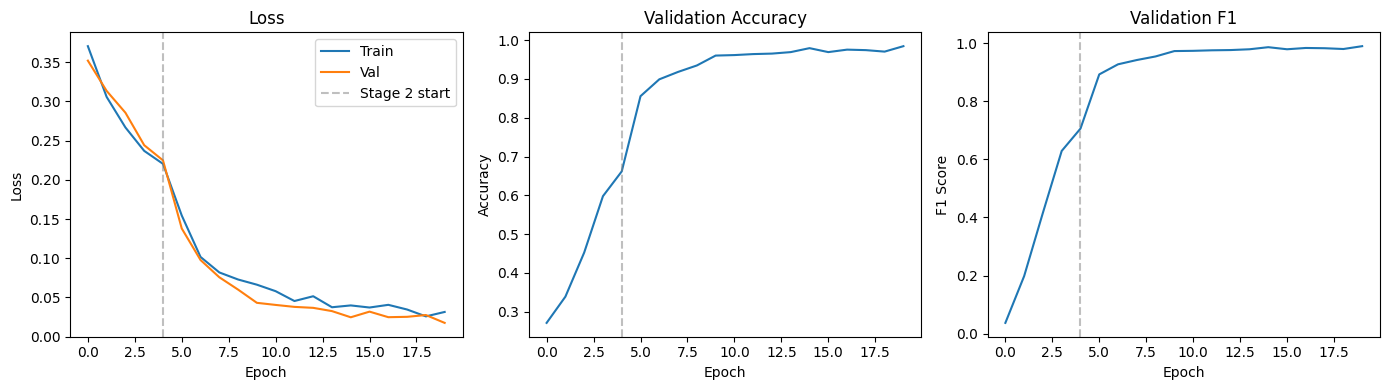


Best Val Acc: 0.985
Best Val F1: 0.990


In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Loss
axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'], label='Val')
axes[0].axvline(x=4, color='gray', linestyle='--', alpha=0.5, label='Stage 2 start')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss')
axes[0].legend()

# Accuracy
axes[1].plot(history['val_acc'])
axes[1].axvline(x=4, color='gray', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Validation Accuracy')

# F1
axes[2].plot(history['val_f1'])
axes[2].axvline(x=4, color='gray', linestyle='--', alpha=0.5)
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('F1 Score')
axes[2].set_title('Validation F1')

plt.tight_layout()
plt.savefig('../outputs/figures/training_curves.png', dpi=150)
plt.show()

print(f"\nBest Val Acc: {max(history['val_acc']):.3f}")
print(f"Best Val F1: {max(history['val_f1']):.3f}")

## 6. Load Best Model & Verify

In [7]:
# Load best checkpoint
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
print(f"Best model from epoch {checkpoint['epoch']}")
print(f"Val metrics: {checkpoint['val_metrics']}")

# Finish W&B run
wandb.finish()

Best model from epoch 15
Val metrics: {'loss': 0.017585212539638826, 'accuracy': 0.9846743295019157, 'precision': 0.9965156794425087, 'recall': 0.9828178694158075, 'f1': 0.9896193771626297}


epoch,▁▁▂▃▃▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
stage1/lr,▁▁▁▁▁
stage1/train_acc,▁▂▅▇█
stage1/train_loss,█▅▃▂▁
stage1/val_acc,▁▂▄▇█
stage1/val_f1,▁▃▅▇█
stage1/val_loss,█▆▄▂▁
stage1/val_precision,████▁
stage1/val_recall,▁▂▄▇█
stage2/lr,██████████████▁
+7,...


**Next:** Phase 6 - Evaluation & Interpretability